# Preprocessing

This notebook consolidates `preprocessing.ipynb` (built on `utils/pipeline_v2.py` which originated from the class files) and `preprocessing_transformers.ipynb` (built on `transformers/pipeline_transformers.py`) into one notebook that prepares the data for every model in the project.

## Pipeline Overview

| Stage | Output | Used by |
|---|---|---|
| Tokenized lyrics (heavy cleaning) | `data/data-w2v/` | GloVe, classic models |
| One train/validation split by song id | `data/splits.parquet`, `data/validation_ids.parquet` | all models |
| Lightly cleaned lyrics, long lyrics handling | `data/data-transformers/` | transformers |
| Averaged GloVe vectors | `data/data-GloVe/` | GloVe models |
| GloVe vectors combined with TF-IDF features | `data/data-Classic/` | classic models (random forest, gradient boosting, naïve bayes, etc) |

## Changes Compared to the Original Notebooks

1. **Data download from Kaggle.** A *Downloading the Data* section fetches `train.csv` / `test.csv` from the [`music-genre` competition](https://www.kaggle.com/competitions/music-genre/data) via the Kaggle API, so the notebook no longer depends on files being placed in `data/` by hand.
2. **NLTK resources are downloaded** in the import cell (`stopwords`, `wordnet`, `punkt`, ...), so the notebook runs in a fresh environment.
3. **Fixed stopword removal.** The cleaning functions come from `utils/pipeline_v3.py`, which combines `utils/pipeline_v2.py` and `transformers/pipeline_transformers.py` (both modules are unchanged). Compared to `pipeline_v2.py` it has these fixes:
   - Stopwords were removed **twice**: once in `regex_cleaner`, *before* contractions were expanded, and again in `main_pipeline`. They are now removed **once**, in `main_pipeline`, after `contractions.fix` and tokenisation.
   - **Negations (*no*, *nor*, *not*) are kept.** NLTK's stopword list contains them, so lines like *"I don't love you"* were reduced to *"love"*, which inverts their meaning for sentiment analysis.
   - **Curly apostrophes (’) are normalised to `'`.** They fell inside the punctuation pattern, so *"don’t"* was split into *"don t"* before it could be expanded, and both halves were then dropped as stopwords.

   `pipeline_v3.py` also keeps the strengths of `pipeline_v2.py`: a wider set of apostrophe look-alikes is normalised, and a final gate keeps only ASCII letter tokens with at least 2 characters that are not stopwords (this also removes single letters and the trailing-space tokens that `unidecode` produces for non-Latin characters).

   | Input | Before | After |
   |---|---|---|
   | I don't love you, no more | `love` | `not love no` |
   | I don’t wanna cry tonight | `want cry tonight` | `not want cry tonight` |
   | You can't stop me, I'm not afraid | `stop afraid` | `not stop not afraid` |

4. **Duplicate songs are removed** from the training data before any cleaning or splitting (from `preprocessing.ipynb`), so copies of the same song cannot end up in both the training and the validation split.
5. **One validation split for all models.** The two notebooks used different splits (one on the raw data, one on the cleaned data). The split is now made once, stratified by genre, on the song `id` of the cleaned training data. It is saved as `data/splits.parquet` and `data/validation_ids.parquet`, so the GloVe, classic and transformer models are all compared on exactly the same validation songs.
6. **Separate transformer input.** Lightly cleaned lyrics plus `id` and metadata are saved to `data-transformers/transformers_train.parquet` and `transformers_test.parquet`.
7. **Long lyrics handling** (functions in `transformers/long_lyrics.py`): measures how many songs exceed the 512-token limit and how many lines repeat within a song, then adds two columns to the transformer files: `lyrics_classification` (repeated lines removed, head + tail truncation for songs still too long) and `lyrics_sentiment` (full lyrics, songs over the limit split into two parts at the stanza break closest to the middle).
8. **GloVe embeddings combined with TF-IDF features.** The averaged GloVe vectors are joined with TF-IDF word weights for the classic models (from `preprocessing.ipynb`).
9. **Class balancing removed.** The `balance_classes` step and its `balanced_train_df.parquet` output are no longer part of the preprocessing.
10. **Fixes carried over.** `stratify` uses `df_train['tag']` (the original referenced an undefined `df`), and the GloVe vocabulary is read from `glove_dir / "vocab.parquet"`, where it is saved.

The environment is described in `requirements.txt` (conda env `text_mining_project`). The notebook runs from the project root or from the `transformers/` folder.

## Setup

Imports, NLTK resources, and the folder structure. The project root is added to `sys.path` for the shared `utils` package, and the `transformers/` folder for `long_lyrics.py`.

In [3]:
%load_ext autoreload
%autoreload 2
import re
import sys
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import polars as pl
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

for pkg in ["stopwords", "wordnet", "omw-1.4", "punkt", "punkt_tab", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

# Works from the project root and from the transformers/ folder
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "transformers" else Path.cwd()
sys.path.append(str(PROJECT_ROOT))                    # shared utils package
sys.path.append(str(PROJECT_ROOT / "transformers"))   # pipeline_transformers.py, long_lyrics.py

from utils.pipeline_v3 import main_pipeline
from utils.funcs import cooccurrence_matrix_generator, song_vector, save_glove_csv
from utils.GloVe import GloVe

In [4]:
data_dir = PROJECT_ROOT / "data"
data_dir.mkdir(parents=True, exist_ok=True)

subfolders = ["data-GloVe", "data-transformers", "data-Classic", "data-w2v"]

for sub in subfolders:
    (data_dir / sub).mkdir(parents=True, exist_ok=True)

glove_dir = data_dir / "data-GloVe"
tran_dir = data_dir / "data-transformers"
clas_dir = data_dir / "data-Classic"
w2v_dir = data_dir / "data-w2v"

## Downloading the Data

The raw data is downloaded from the [Kaggle competition page](https://www.kaggle.com/competitions/music-genre/data) with the official Kaggle API and extracted into `data/`. The download is skipped if the files are already present.

This requires a Kaggle API token (`kaggle auth login`, or a token from *Kaggle → Settings → API*) and having accepted the competition rules on the competition page.

**Note:** an old `~/.kaggle/kaggle.json` API key takes precedence over a `kaggle auth login` session. If that key is expired, the download fails with `401 Unauthorized` even after logging in; rename or remove `kaggle.json` to fix it.

In [6]:
if not (data_dir / "train.csv").exists():
    from kaggle.api.kaggle_api_extended import KaggleApi
    api = KaggleApi()
    api.authenticate()
    api.competition_download_files("music-genre", path=data_dir, quiet=False)
    with zipfile.ZipFile(data_dir / "music-genre.zip") as z:
        z.extractall(data_dir)
    (data_dir / "music-genre.zip").unlink()

sorted(p.name for p in data_dir.iterdir())

100%|██████████| 95.9M/95.9M [00:03<00:00, 27.7MB/s]


['data-Classic',
 'data-GloVe',
 'data-transformers',
 'data-w2v',
 'sample_submission.csv',
 'test.csv',
 'train.csv']

## Reading the Training Data

To optimize data preprocessing in the pipeline, we load the raw data into a **Polars DataFrame**, leveraging its multi-threaded engine to handle large files faster and more efficiently than pandas.

In [7]:
df_train = pl.read_csv(data_dir / "train.csv")
df_test = pl.read_csv(data_dir / "test.csv")

### Removing Duplicate Songs

Lyrics sites often contain the same song more than once (covers, remasters, re-uploads). If one copy ends up in the training split and another in the validation split, the model is rewarded for memorizing instead of generalizing. Exact duplicates are therefore removed from the training data **before** any cleaning or splitting. The number of test lyrics that also appear in the training data is printed for reference only; test rows are never dropped.

In [8]:
print("train rows before:", df_train.height)
print("duplicate lyrics in train:", df_train["lyrics"].is_duplicated().sum())
print("test lyrics also in train:", df_test["lyrics"].is_in(df_train["lyrics"].implode()).sum())

# keep the first copy of every song; the test set is left untouched because every id needs a prediction
df_train = df_train.unique(subset="lyrics", keep="first", maintain_order=True)
print("train rows after:", df_train.height)

train rows before: 134967
duplicate lyrics in train: 343
test lyrics also in train: 77
train rows after: 134789


## Tokenized Lyrics for GloVe and Classic Models

To manage local memory constraints, the training data is split into two equal partitions (`sample_df1` and `sample_df2`), stratified by genre, and processed sequentially.

### Lyrics Preprocessing Overview

Each partition is mapped through `main_pipeline` via Polars' `map_elements` to clean and standardize the `lyrics` column:

- **Text Cleaning & Normalization:** Strips song metadata tags (e.g., *[Chorus]*, *[Verse]*), URLs, brackets, and punctuation, while expanding contractions.
- **Filtering & Tokenization:** Tokenizes text into individual words, discards non-alphabetic tokens, and removes standard English stopwords (once, after contractions are expanded, keeping the negations *no*, *nor*, *not*) as well as common musical filler vocalizations (e.g., *"oh"*, *"yeah"*, *"la"*).
- **Linguistic Standardization:** Converts diacritics to ASCII, applies lowercasing, and lemmatizes tokens across multiple parts of speech.
- **Output Schema:** With `tokenized_output=True`, each song's lyrics are transformed into a list of cleaned tokens (`pl.List(pl.String)`) stored under `cleaned_lyrics`.

Once both batches finish processing, they are combined back into a single unified dataset (`cleaned_df_train`) using vertical concatenation (`pl.concat`). Training songs with 10 tokens or fewer carry too little signal and are dropped; test songs are never dropped.

In [10]:
def tokenize_lyrics(df):
    """Add the tokenized `cleaned_lyrics` column (list of tokens) to a DataFrame."""
    return df.with_columns(
        pl.col("lyrics")
        .map_elements(lambda x: main_pipeline(x, tokenized_output=True), return_dtype=pl.List(pl.String))
        .alias("cleaned_lyrics")
    )

sample_df1, sample_df2 = train_test_split(
    df_train,
    train_size=0.5,
    stratify=df_train["tag"],
    random_state=80085
)

cleaned_df_train = pl.concat([tokenize_lyrics(sample_df1), tokenize_lyrics(sample_df2)]).filter(
    pl.col("cleaned_lyrics").list.len() > 10
)
cleaned_df_test = tokenize_lyrics(df_test)

print("train songs kept:", cleaned_df_train.height, "| test songs:", cleaned_df_test.height)

train songs kept: 134525 | test songs: 33742


## Checkpointing & Class Distribution Overview

To preserve our preprocessed data and avoid redundant recomputation, we export the DataFrame to **Parquet format** and reload it. Parquet provides efficient column-oriented compression and natively preserves complex nested schemas, such as columns containing lists of strings (`pl.List(pl.String)`).

An initial inspection of the target genre distribution reveals a notable class imbalance, with **Rock**, **Pop**, and **Rap** making up the substantial majority of the dataset. The data is deliberately **not** rebalanced here, so downstream modeling and evaluation strategies need to account for this skew.

In [ ]:
cleaned_df_train.select(["id", "tag", "cleaned_lyrics"]).write_parquet(w2v_dir / "cleaned_train_df_tokenized.parquet")
cleaned_df_test.select(["id", "cleaned_lyrics"]).write_parquet(w2v_dir / "cleaned_test_df_tokenized.parquet")

In [5]:
cleaned_df_train = pl.read_parquet(w2v_dir / "cleaned_train_df_tokenized.parquet")
cleaned_df_test = pl.read_parquet(w2v_dir / "cleaned_test_df_tokenized.parquet")

In [6]:
cleaned_df_train["tag"].value_counts().sort("count", descending=True)

tag,count
str,u32
"""pop""",55477
"""rap""",38528
"""rock""",25275
"""rb""",6191
"""misc""",5593
"""country""",3461


### Lyric Length Distribution

Token counts per song for train and test, and per genre for train (test has no labels). The histograms are clipped at the 99th percentile so a few extremely long songs do not squash the plot.

train: n=134525, mean=156, median=117, p95=341, p99=627, max=9750
test: n=33742, mean=158, median=117, p95=344, p99=653, max=8133


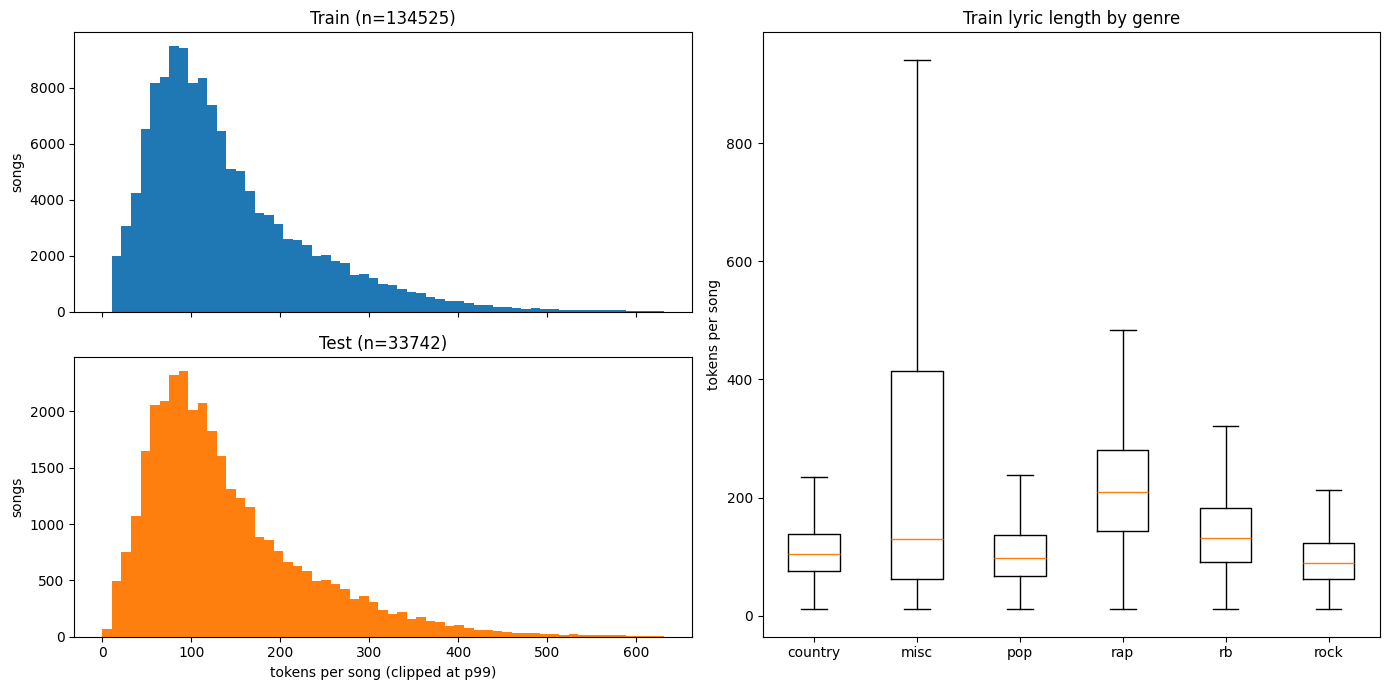

In [7]:
len_train = cleaned_df_train["cleaned_lyrics"].list.len().to_numpy()
len_test = cleaned_df_test["cleaned_lyrics"].list.len().to_numpy()

for name, lens in [("train", len_train), ("test", len_test)]:
    print(f"{name}: n={len(lens)}, mean={lens.mean():.0f}, median={np.median(lens):.0f}, "
          f"p95={np.percentile(lens, 95):.0f}, p99={np.percentile(lens, 99):.0f}, max={lens.max()}")

clip = int(np.percentile(np.concatenate([len_train, len_test]), 99))
bins = np.linspace(0, clip, 60)

tags = sorted(cleaned_df_train["tag"].unique().to_list())
data = [len_train[(cleaned_df_train["tag"] == t).to_numpy()] for t in tags]

# left: train histogram over test histogram, right: train boxplot per genre
fig = plt.figure(figsize=(14, 7))
gs = fig.add_gridspec(2, 2)
ax_train = fig.add_subplot(gs[0, 0])
ax_test = fig.add_subplot(gs[1, 0], sharex=ax_train)
ax_box = fig.add_subplot(gs[:, 1])

ax_train.hist(len_train, bins=bins, color="tab:blue")
ax_train.set_title(f"Train (n={len(len_train)})")
ax_train.set_ylabel("songs")
ax_train.tick_params(labelbottom=False)

ax_test.hist(len_test, bins=bins, color="tab:orange")
ax_test.set_title(f"Test (n={len(len_test)})")
ax_test.set_ylabel("songs")
ax_test.set_xlabel("tokens per song (clipped at p99)")

ax_box.boxplot(data, tick_labels=tags, showfliers=False)
ax_box.set_title("Train lyric length by genre")
ax_box.set_ylabel("tokens per song")

plt.tight_layout()
plt.show()

### Most Frequent Words per Genre

The most frequent tokens of the cleaned training songs, per genre. Counts are total occurrences across all songs of that genre, after cleaning (stopwords removed, negations kept). Each panel shows the top 15 words of one genre.

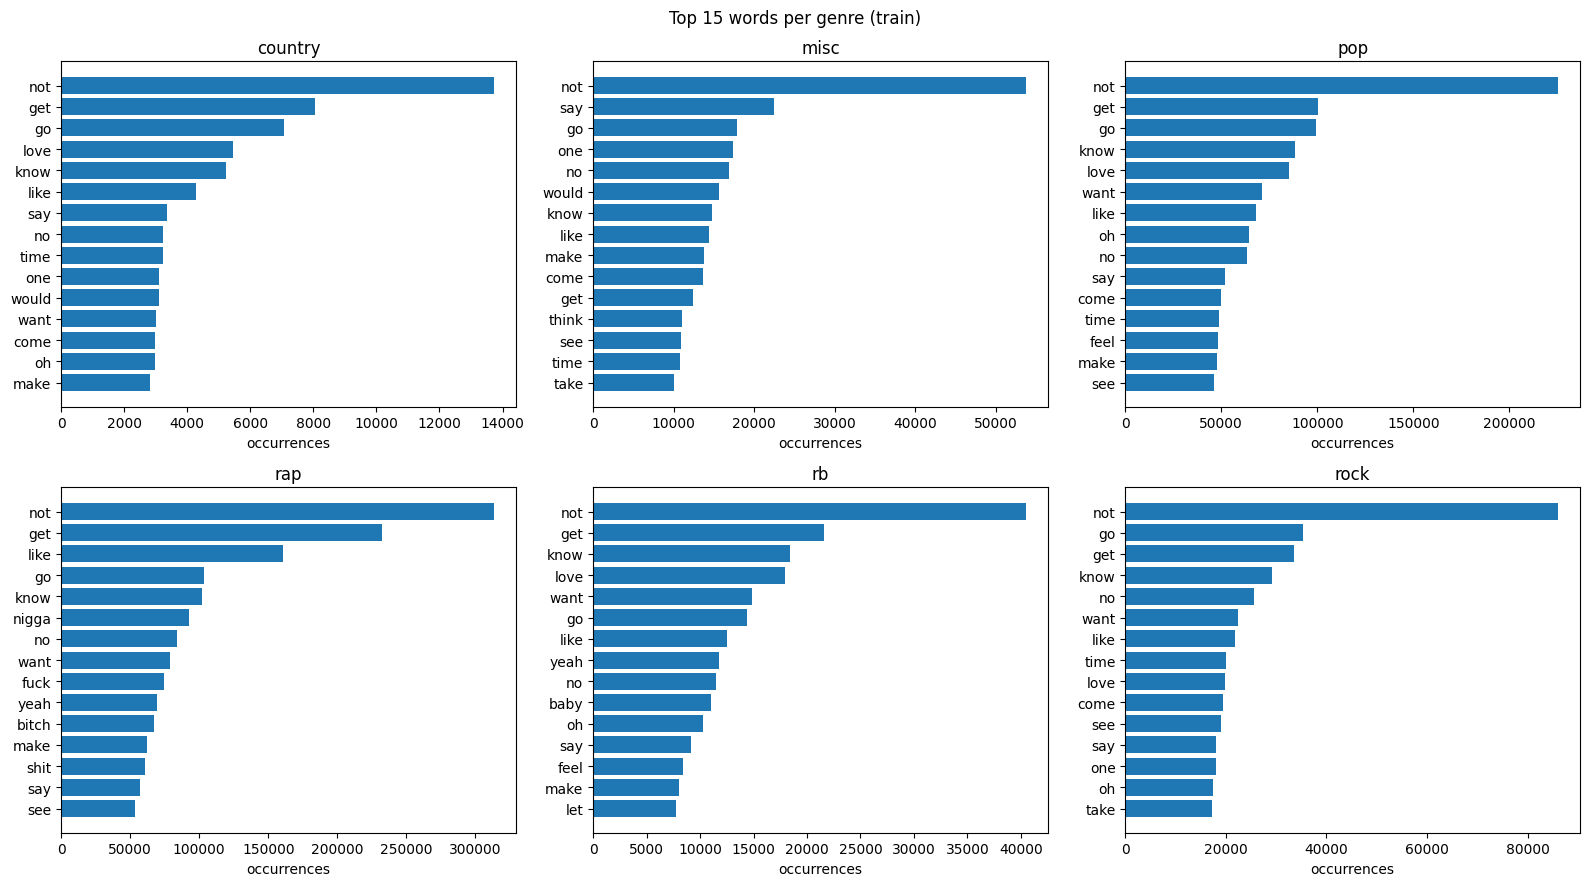

In [8]:
TOP_N = 15
genres = sorted(cleaned_df_train["tag"].unique().to_list())

# total occurrences of every token per genre, then the TOP_N most frequent per genre
word_counts = (cleaned_df_train.select("tag", "cleaned_lyrics")
               .explode("cleaned_lyrics")
               .group_by("tag", "cleaned_lyrics").len()
               .rename({"cleaned_lyrics": "word", "len": "count"}))
top_words = word_counts.sort("count", descending=True).group_by("tag").head(TOP_N)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, genre in zip(axes.flat, genres):
    part = top_words.filter(pl.col("tag") == genre).sort("count")
    ax.barh(part["word"], part["count"], color="tab:blue")
    ax.set_title(genre)
    ax.set_xlabel("occurrences")
for ax in axes.flat[len(genres):]:
    ax.set_visible(False)

fig.suptitle(f"Top {TOP_N} words per genre (train)")
plt.tight_layout()
plt.show()

## Train/Validation Split by Song ID

The cleaned training songs are split 75/25, stratified by genre, so the validation set keeps the natural genre distribution. The split is made once, on the song `id`, and reused by every branch: the same split is applied to the tokenized lyrics (GloVe, TF-IDF) and to the transformer input. It is reproducible (same `train.csv` and seed give the same songs), and every model, whatever its preprocessing, can be evaluated on exactly the same validation songs by filtering on these ids.

Everything that learns from data (co-occurrence matrix, GloVe, TF-IDF) is fitted on `X_train` only. The song ids of both parts are saved to `data/splits.parquet` (train and validation, in the same row order as the feature files) and the validation ids alone to `data/validation_ids.parquet`.

In [14]:
X = cleaned_df_train.select("id", "cleaned_lyrics")
y = cleaned_df_train.select("tag")

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=80085, stratify=y
)

splits = pl.concat([
    X_train.select("id").with_columns(pl.lit("train").alias("split")),
    X_val.select("id").with_columns(pl.lit("val").alias("split")),
])
splits.write_parquet(data_dir / "splits.parquet")
X_val.select("id").write_parquet(data_dir / "validation_ids.parquet")

print(f"train: {X_train.height} songs, validation: {X_val.height} songs")

train: 100893 songs, validation: 33632 songs


## Transformer Input

Transformer models read words in context and use their own subword tokenizer, so they get the lyrics with only **light cleaning** instead of the tokenized version above: stopwords, punctuation, contractions, casing and line breaks are kept, since removing them changes the meaning of a line (e.g. *"Cause it's over now"* consists only of stopwords). Only noise is removed: square-bracket annotations (section tags such as *[Verse 1: Artist]*, *[Chorus]* and Genius' *[?]* marker for unknown lyrics), URLs and invisible characters, plus redundant whitespace. Lyrics in parentheses are kept, as they are usually sung backing vocals.

The training songs are restricted to the songs of the split above, so the transformer files contain exactly the same songs as the tokenized files. The saved files (end of the *Long Lyrics* section) keep `id` and the song metadata (`year`, `views`, ...) needed for the sentiment analysis and the Kaggle submission.

In [15]:
square_brackets = re.compile(r"\[[^\]\n]*\]")
url_pattern = re.compile(r"(?:https?://|www\.)\S+")
invisible_chars = re.compile("[​﻿]")
spaces = re.compile(r"[ \t]+")
extra_blank_lines = re.compile(r"\n{3,}")

def light_clean(text):
    text = text.replace("’", "'").replace("‘", "'")
    text = square_brackets.sub("", text)
    text = url_pattern.sub("", text)
    text = invisible_chars.sub("", text)
    text = spaces.sub(" ", text)
    text = "\n".join(line.strip() for line in text.split("\n"))
    return extra_blank_lines.sub("\n\n", text).strip()   # keeps one blank line between stanzas

metadata = ["id", "title", "artist", "year", "views", "features"]

tr_train = (df_train.filter(pl.col("id").is_in(splits["id"].implode()))
                    .with_columns(pl.col("lyrics").map_elements(light_clean, return_dtype=pl.String))
                    .select(metadata + ["tag", "lyrics"]))
tr_test = (df_test.with_columns(pl.col("lyrics").map_elements(light_clean, return_dtype=pl.String))
                  .select(metadata + ["lyrics"]))

assert tr_train.height == splits.height, "transformer train songs differ from the split"
print(f"transformer input: {tr_train.height} train songs, {tr_test.height} test songs")

transformer input: 134525 train songs, 33742 test songs


### Long Lyrics and the 512-Token Limit

Transformer encoders such as RoBERTa read at most 512 tokens, i.e. 510 tokens of lyrics plus two special tokens; anything beyond is cut off. Token counts are measured with the tokenizer of `distilroberta-base`, which uses the same byte-level BPE vocabulary as RoBERTa-based sentiment models (e.g. `cardiffnlp/twitter-roberta-base-sentiment-latest`), so the counts hold for both tasks. Only the tokenizer files are downloaded here, no model weights.

The two tasks handle long songs differently:
- **Genre classification:** repeated lines (mostly choruses) are removed first, as they add length without new content. Songs that are still too long are reduced to their first 128 and last 381 tokens (*head + tail*), the truncation strategy that performed best for long texts in Sun et al. (2019).
- **Sentiment analysis:** the sentiment of the *whole* song is of interest and repetition is part of a song's emotional emphasis, so the full lyrics are kept. Songs that are too long are split into two parts at the stanza break closest to the middle; each part is scored separately and the song's score is the token-length-weighted average of both parts (`average_part_scores`).

*Sun, C., Qiu, X., Xu, Y., & Huang, X. (2019). How to Fine-Tune BERT for Text Classification? In* Chinese Computational Linguistics (CCL 2019)*, LNCS 11856, 194–206. Springer.*

In [16]:
from transformers import AutoTokenizer
from utils.long_lyrics import (MAX_TOKENS, token_counts, repeated_lines, remove_repeated_lines,
                         head_tail, split_in_two)

tokenizer = AutoTokenizer.from_pretrained("distilroberta-base")

n_tokens_train = token_counts(tr_train["lyrics"].to_list(), tokenizer)
n_tokens_test = token_counts(tr_test["lyrics"].to_list(), tokenizer)
print(f"songs over {MAX_TOKENS} tokens: {(n_tokens_train > MAX_TOKENS).mean():.1%} (train), "
      f"{(n_tokens_test > MAX_TOKENS).mean():.1%} (test)")

c:\Users\Lucas\anaconda3\envs\text-mining\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Lucas\anaconda3\envs\text-mining\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Lucas\.cache\huggingface\hub\models--distilroberta-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activ

songs over 510 tokens: 26.2% (train), 26.3% (test)


#### Repeated Lines

A line counts as repeated if the same line (ignoring casing and surrounding whitespace) already appeared earlier in the same song. Only these repeats are removed; the first occurrence of every line is kept.

In [17]:
line_stats = np.array([repeated_lines(t) for t in tr_train["lyrics"]])
repeats = tr_train.select("tag").with_columns(lines=line_stats[:, 0], repeated=line_stats[:, 1])

print(f"{repeats['repeated'].sum():,} of {repeats['lines'].sum():,} lines "
      f"({repeats['repeated'].sum() / repeats['lines'].sum():.1%}) repeat an earlier line of the same song")
print(f"{(repeats['repeated'] > 0).mean():.1%} of songs contain at least one repeated line")

(repeats.group_by("tag")
        .agg(share_of_lines_repeated=(pl.col("repeated").sum() / pl.col("lines").sum()).round(3),
             median_repeated_lines=pl.col("repeated").median())
        .sort("tag"))

1,415,174 of 5,619,986 lines (25.2%) repeat an earlier line of the same song
81.4% of songs contain at least one repeated line


tag,share_of_lines_repeated,median_repeated_lines
str,f64,f64
"""country""",0.286,7.0
"""misc""",0.081,0.0
"""pop""",0.313,8.0
"""rap""",0.196,8.0
"""rb""",0.309,12.0
"""rock""",0.284,7.0


In [18]:
deduped_train = [remove_repeated_lines(t) for t in tr_train["lyrics"]]
deduped_test = [remove_repeated_lines(t) for t in tr_test["lyrics"]]
n_dedup_train = token_counts(deduped_train, tokenizer)
n_dedup_test = token_counts(deduped_test, tokenizer)

overflow = tr_train.select("tag").with_columns(before=n_tokens_train > MAX_TOKENS, after=n_dedup_train > MAX_TOKENS)
print(f"songs over {MAX_TOKENS} tokens: {overflow['before'].mean():.1%} -> {overflow['after'].mean():.1%} "
      f"after removing repeated lines")
overflow.group_by("tag").agg(pl.col("before", "after").mean().round(3)).sort("tag")

songs over 510 tokens: 26.2% -> 16.1% after removing repeated lines


tag,before,after
str,f64,f64
"""country""",0.065,0.02
"""misc""",0.404,0.385
"""pop""",0.116,0.035
"""rap""",0.6,0.429
"""rb""",0.303,0.104
"""rock""",0.055,0.015


#### Classification Input: Head + Tail

The songs that are still over the limit after removing repeated lines are truncated to their first 128 and last 381 tokens, joined by a line break.

In [19]:
tr_train = tr_train.with_columns(lyrics_classification=pl.Series(
    [head_tail(t, tokenizer) if n > MAX_TOKENS else t for t, n in zip(deduped_train, n_dedup_train)]))
tr_test = tr_test.with_columns(lyrics_classification=pl.Series(
    [head_tail(t, tokenizer) if n > MAX_TOKENS else t for t, n in zip(deduped_test, n_dedup_test)]))

n_final = token_counts(tr_train["lyrics_classification"].to_list(), tokenizer)
print(f"head + tail applied to {(n_dedup_train > MAX_TOKENS).mean():.1%} of training songs; "
      f"longest classification input: {n_final.max()} tokens")

head + tail applied to 16.1% of training songs; longest classification input: 510 tokens


#### Sentiment Input: Two Parts

Songs over the limit are split into two parts (see `split_in_two`). Songs longer than twice the limit still have parts over 510 tokens; these parts are truncated when scored.

In [20]:
tr_train = tr_train.with_columns(lyrics_sentiment=pl.Series(
    [split_in_two(t, tokenizer) if n > MAX_TOKENS else [t] for t, n in zip(tr_train["lyrics"], n_tokens_train)]))
tr_test = tr_test.with_columns(lyrics_sentiment=pl.Series(
    [split_in_two(t, tokenizer) if n > MAX_TOKENS else [t] for t, n in zip(tr_test["lyrics"], n_tokens_test)]))

split_songs = tr_train.filter(pl.col("lyrics_sentiment").list.len() == 2)
part_lengths = token_counts(split_songs["lyrics_sentiment"].explode().to_list(), tokenizer).reshape(-1, 2)
print(f"{len(split_songs) / len(tr_train):.1%} of training songs split into two parts")
print(f"median part lengths: {np.median(part_lengths, axis=0)} tokens; "
      f"songs with a part still over {MAX_TOKENS} tokens: {(part_lengths.max(axis=1) > MAX_TOKENS).sum()}")

26.2% of training songs split into two parts
median part lengths: [349. 351.] tokens; songs with a part still over 510 tokens: 7118


#### Saving the Transformer Files

Both transformer files contain `id`, the metadata, the raw (lightly cleaned) `lyrics`, and the two long lyrics columns `lyrics_classification` and `lyrics_sentiment`. The training file also holds the genre `tag`. The validation songs are selected with `data/validation_ids.parquet`.

In [21]:
tr_train.write_parquet(tran_dir / "transformers_train.parquet")
tr_test.write_parquet(tran_dir / "transformers_test.parquet")
tr_train.select("id", "tag", "lyrics_classification", "lyrics_sentiment").head(3)

id,tag,lyrics_classification,lyrics_sentiment
i64,str,str,list[str]
535805,"""rock""","""When you said you loved me Did…","[""When you said you loved me Did you mean it then Did you change your mind one day Or was it all pretend Cause it's over now See you walk away See you walk away Seems like nothing's gonna change""]"
7519483,"""rap""","""Kid Naruto Rap Everybody want…","[""Kid Naruto Rap Everybody wants you to hurt Everybody wants you to cry with your face In the dirt Gotta put in time, gotta work Everybody's praying that I fall But I gotta make it work Everybody wants you to hurt Everybody wants you to cry with your face In the dirt Gotta put in time, gotta work Everybody's praying that I fall But I gotta make it Hoping it might work out one day Wrong Do it yourself or you might as well fall Gotta do the grind If you never wanna fall Better Aim for the top or you never won at all As a kid I had nobody Grew up parentless Had to go and be funny Had to hide the pain some way On my own path That's my ninja way Headed for the top On a day to day They treat me like outcast Got Stay out the way Gotta hide emotions Gotta hidе the pain This demon fox inside Keeps on driving mе insane Everybody wants you to hurt Everybody wants you to cry with your face In the dirt Gotta put in time, gotta work Everybody's praying that I fall But I gotta make it work"", ""Everybody wants you to hurt Everybody wants you to cry with your face In the dirt Gotta put in time, gotta work Everybody's praying that I fall But I gotta make it Ima be the fucking goat don't need no confirmation You can't replicate my jutsu you ain't as amazing That nigga swear he up to par stop the fabricating I told y'all I'm a sage and y'all ain't got the proper training I ain't have no friends or family helping at all I got demons all Inside of me I'm telling you I'm scarred I had teachers left and right telling me I won't make it far When you different everybody only focus on your flaws Everybody wants you to hurt Everybody wants you to cry with your face In the dirt Gotta put in time, gotta work Everybody's praying that I fall But I gotta make it work Everybody wants you to hurt Everybody wants you to cry with your face In the dirt Gotta put in time, gotta work Everybody's praying that I fall But I gotta make it work Everybody wants you to hurt Everybody wants you to cry with your face In the dirt Gotta put in time, gotta work Everybody's praying that I fall But I gotta make it""]"
4892808,"""pop""","""People tell me I've changed I …","[""People tell me I've changed I find it hard to explain Maybe I feel the same Don't know how to make it better, better again They say I must be happy now Got it all figured out I guess it's gotta hurt sometimes This is what I asked for This is what I asked for, right? All the things that I've done Countless times I've been wrong Maybe that's how you learn But I just wanna make it better, better again They say I must be happy now Got it all figured out I guess it's gotta hurt sometimes This is what I asked for This is what I asked for, right? This is what I asked for This is what I asked for, right?""]"


## Dataset Branching: Co-Occurrence Matrix Generation

Rather than restricting downstream modeling to a single architecture, we branch our data preparation to support varied embedding strategies, ranging from traditional distributional methods (Word2Vec, GloVe) to deep sequence models (Transformers). The transformer branch is handled above; the GloVe branch follows.

### Co-Occurrence Computation
Count-based embeddings require pairwise co-occurrence frequencies across the corpus. Computing a full co-occurrence matrix naively can trigger SciPy out-of-memory errors due to quadratic vocabulary growth.

We run `cooccurrence_matrix_generator` on the training split to slice matrix operations into manageable chunks, prune self-co-occurrences, and persist the output as a compact Parquet file (`data/data-GloVe/cooccurrence_matrix.parquet`).

In [22]:
df_cooccurrence = cooccurrence_matrix_generator(X_train, "cleaned_lyrics")
df_cooccurrence.write_parquet(glove_dir / "cooccurrence_matrix.parquet")

Computing pairs in blocks: 100%|██████████| 30/30 [00:23<00:00,  1.28it/s]


Assembling final co-occurrence table...


### Vocabulary and Training Pairs

The vocabulary is limited to the 100k most frequent words, pairs that occur only once are dropped as noise, and words are encoded as integer ids. The result is written to disk in chunks (`pairs.parquet`, `vocab.parquet`), then shuffled once and stored as `.npy` arrays for GloVe training.

In [23]:
cooc_matrix = pl.scan_parquet(glove_dir / "cooccurrence_matrix.parquet")
# how many distinct words? (cheap, works on the integer codes)
print(cooc_matrix.select(pl.col("word_1").n_unique()).collect(engine="streaming"))

# the 100k most frequent words
top = (cooc_matrix.group_by("word_1").agg(pl.col("count").sum())
         .sort("count", descending=True).head(100_000)
         .collect(engine="streaming")["word_1"].cast(pl.String))
vocab = top.sort()
enum = pl.Enum(vocab)

# filter, encode to ids, and write to disk, all in chunks
(cooc_matrix.filter(pl.col("count") > 1)                          # drops most of the noise first
   .with_columns(pl.col("word_1", "word_2").cast(pl.String))
   .filter(pl.col("word_1").is_in(vocab.implode()) & pl.col("word_2").is_in(vocab.implode()))
   .select(pl.col("word_1").cast(enum).to_physical().cast(pl.Int32).alias("i"),
           pl.col("word_2").cast(enum).to_physical().cast(pl.Int32).alias("j"),
           pl.col("count").cast(pl.Float32).alias("x"))
   .sink_parquet(glove_dir / "pairs.parquet"))

vocab.to_frame("word").write_parquet(glove_dir / "vocab.parquet")
print("pairs kept:", pl.scan_parquet(glove_dir / "pairs.parquet").select(pl.len()).collect())

<sys>:0: UserWarning: POLARS_MAX_BLOCKING_THREAD_COUNT reached (512), this may indicate a deadlock


shape: (1, 1)
┌────────┐
│ word_1 │
│ ---    │
│ u32    │
╞════════╡
│ 148103 │
└────────┘
pairs kept: shape: (1, 1)
┌──────────┐
│ len      │
│ ---      │
│ u32      │
╞══════════╡
│ 91909922 │
└──────────┘


In [24]:
pairs = pl.read_parquet(glove_dir / "pairs.parquet")
i, j, x = pairs["i"].to_numpy(), pairs["j"].to_numpy(), pairs["x"].to_numpy()
del pairs

idx = np.arange(len(x), dtype=np.int32)
np.random.default_rng(0).shuffle(idx)
np.save(glove_dir / "i.npy", i[idx]); np.save(glove_dir / "j.npy", j[idx]); np.save(glove_dir / "x.npy", x[idx])
del i, j, x, idx

### GloVe Training

A 25 dimensional GloVe model is trained on the shuffled co-occurrence pairs. The nearest neighbours of *love* serve as a quick sanity check of the embedding.

In [25]:
vocab = pl.read_parquet(glove_dir / "vocab.parquet")["word"]
glove = GloVe(vocab, dim=25).fit(glove_dir / "i.npy", glove_dir / "j.npy", glove_dir / "x.npy", epochs=30)
print(glove.most_similar("love"))
glove.save(glove_dir / "glove_25d")

c:\Users\Lucas\Github\Music-Genre-Identifier\utils\GloVe.py:73: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:209.)
  return torch.as_tensor(np.asarray(arr), dtype=dtype, device=self.device)


epoch 1/30  loss 0.1609
epoch 2/30  loss 0.0240
epoch 3/30  loss 0.0211
epoch 4/30  loss 0.0178
epoch 5/30  loss 0.0148
epoch 6/30  loss 0.0134
epoch 7/30  loss 0.0126
epoch 8/30  loss 0.0121
epoch 9/30  loss 0.0117
epoch 10/30  loss 0.0114
epoch 11/30  loss 0.0111
epoch 12/30  loss 0.0110
epoch 13/30  loss 0.0108
epoch 14/30  loss 0.0107
epoch 15/30  loss 0.0106
epoch 16/30  loss 0.0104
epoch 17/30  loss 0.0103
epoch 18/30  loss 0.0102
epoch 19/30  loss 0.0101
epoch 20/30  loss 0.0100
epoch 21/30  loss 0.0099
epoch 22/30  loss 0.0099
epoch 23/30  loss 0.0098
epoch 24/30  loss 0.0097
epoch 25/30  loss 0.0097
epoch 26/30  loss 0.0096
epoch 27/30  loss 0.0096
epoch 28/30  loss 0.0095
epoch 29/30  loss 0.0094
epoch 30/30  loss 0.0094
[('let', 0.994), ('see', 0.992), ('way', 0.992), ('go', 0.991), ('know', 0.991), ('never', 0.991), ('feel', 0.991), ('think', 0.991)]


### Visualizing the Word Embeddings with UMAP

The 25 dimensional GloVe vectors of the 5000 most frequent words are projected to 2D with UMAP (`pip install umap-learn`), so words used in similar contexts end up close together. Each word is colored by its **main genre**: the genre where it is used most *relative to the size of that genre* (raw counts would assign almost every word to the large genres pop and rap). The words most specific to each genre are labeled.

The vectors are mean-centered and compared with cosine distance, because the GloVe vectors of frequent words share a large common component (the nearest neighbors of *love* all have a cosine similarity of about 0.99), which would otherwise hide the structure.

c:\Users\Lucas\anaconda3\envs\text-mining\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


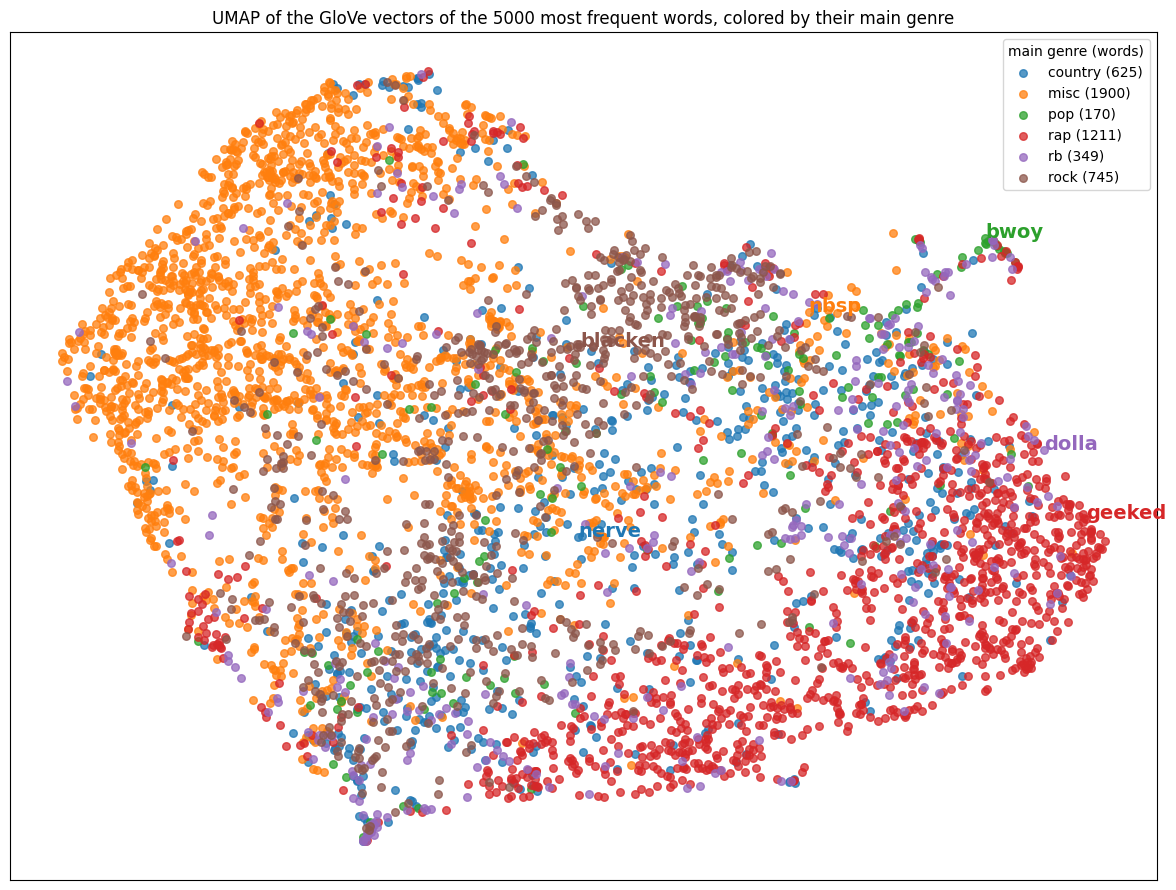

In [ ]:
import umap

TOP_WORDS = 5000
LABELS_PER_GENRE = 5

glove_vectors, glove_vocab = GloVe.load_vectors(glove_dir / "glove_25d")
glove_index = {word: k for k, word in enumerate(glove_vocab)}

# the TOP_WORDS most frequent words that have a GloVe vector (word_counts and genres come from the
# "Most Frequent Words per Genre" section)
plot_words = (word_counts.group_by("word").agg(pl.col("count").sum().alias("total"))
              .filter(pl.col("word").is_in(glove_vocab))
              .sort("total", descending=True).head(TOP_WORDS))

# genre of a word = the genre where it is used most, relative to the size of that genre
# (raw counts would give almost every word to pop and rap)
genre_size = word_counts.group_by("tag").agg(pl.col("count").sum().alias("size"))
word_genre = (word_counts.join(genre_size, on="tag")
              .filter(pl.col("word").is_in(plot_words["word"].implode()))
              .with_columns((pl.col("count") / pl.col("size")).alias("rel_freq"))
              .with_columns((pl.col("rel_freq") / pl.col("rel_freq").sum().over("word")).alias("share"))
              .group_by("word").agg(pl.col("tag").sort_by("share").last().alias("genre"),
                                    pl.col("share").max().alias("purity")))   # share of the word's usage in its main genre
plot_words = plot_words.join(word_genre, on="word").sort("total", descending=True)

X_words = glove_vectors[[glove_index[w] for w in plot_words["word"]]]
X_words = X_words - X_words.mean(axis=0)
embedding = umap.UMAP(n_neighbors=10, min_dist=0.2, metric="cosine", random_state=80085).fit_transform(X_words)

fig, ax = plt.subplots(figsize=(12, 9))
purity = plot_words["purity"].to_numpy()



for k, genre in enumerate(genres):
    mask = (plot_words["genre"] == genre).to_numpy()
    genre_color = f"C{k}"

    ax.scatter(
        embedding[mask, 0],
        embedding[mask, 1],
        s=30,
        alpha=0.75,
        color=genre_color,
        label=f"{genre} ({mask.sum()})",
    )

    # Label the words most specific to each genre in the genre's color
    top_indices = np.flatnonzero(mask)[np.argsort(-purity[mask])[:LABELS_PER_GENRE]]
    for idx in top_indices:
        ax.annotate(
            plot_words["word"][int(idx)],
            embedding[idx],
            color=genre_color,
            fontsize=14,
            weight="bold",
        )

ax.set_title(
    f"UMAP of the GloVe vectors of the {TOP_WORDS} most frequent words, colored by their main genre"
)
ax.set_xticks([])
ax.set_yticks([])

# Create legend and explicitly normalize legend marker sizes
leg = ax.legend(title="main genre (words)")
for handle in leg.legend_handles:
    handle.set_sizes([30])  # Desired marker size in the legend

plt.tight_layout()
plt.show()

### Song Vectors

Each song is represented by the mean of the GloVe vectors of its tokens (`song_vector`; words outside the vocabulary are skipped, and a song without known words becomes a zero vector). The vectors come from the project's own GloVe model in `utils/GloVe.py`, loaded with `GloVe.load_vectors` so no retraining is needed. The training and validation vectors are saved together with the genre label as CSV files in `data-GloVe`.

**Implementation note.** `utils/GloVe.py` is a PyTorch implementation of the GloVe objective (Pennington et al., 2014). Each word has a vector w, a context vector c, and a bias. The model learns w_i · c_j + b_i + b_j ≈ log(X_ij) for the co-occurrence count X_ij, minimising a weighted squared error. The weight is f(x) = min(1, x / 100)^0.75, so rare pairs count less and very frequent pairs cannot dominate. Training uses Adagrad on mini-batches read from memory-mapped .npy files, so the pairs never need to fit in memory. Each word's final vector is w + c, saved as glove_25d.npy with its vocabulary in glove_25d_vocab.parquet.

In [26]:
vectors, vocab = GloVe.load_vectors(glove_dir / "glove_25d")
index = {word: k for k, word in enumerate(vocab)}

X_train_glove = np.vstack([song_vector(t, vectors, index) for t in X_train["cleaned_lyrics"]])
X_val_glove = np.vstack([song_vector(t, vectors, index) for t in X_val["cleaned_lyrics"]])
X_test_glove = np.vstack([song_vector(t, vectors, index) for t in cleaned_df_test["cleaned_lyrics"]])

print(X_train_glove.shape, X_val_glove.shape, X_test_glove.shape)

(100893, 25) (33632, 25) (33742, 25)


In [31]:
train_glove = save_glove_csv(X_train_glove, y_train, glove_dir / "train_glove.csv")
val_glove = save_glove_csv(X_val_glove, y_val, glove_dir / "val_glove.csv")
test_glove = pl.DataFrame(X_test_glove, schema=[f"dim_{k}" for k in range(X_test_glove.shape[1])], orient="row")
test_glove.write_csv(glove_dir / "test_glove.csv")

print(train_glove.shape)
train_glove.head()
train_glove.head()

(100893, 26)


dim_0,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7,dim_8,dim_9,dim_10,dim_11,dim_12,dim_13,dim_14,dim_15,dim_16,dim_17,dim_18,dim_19,dim_20,dim_21,dim_22,dim_23,dim_24,genre
f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,str
-0.915205,-0.738503,-0.93499,0.951644,0.912723,-1.039462,0.938011,-1.06347,-0.882141,0.964697,-0.897292,0.830341,1.193435,0.773519,0.935322,-0.855055,-1.017996,-1.012103,-1.037993,-1.030151,-0.760057,0.990285,0.914478,0.996502,-0.56602,"""pop"""
-0.684437,-0.314899,-0.849869,0.816059,0.886154,-0.736979,0.834923,-0.349312,-0.66005,0.335444,-0.743644,0.55932,0.009959,0.19659,0.575996,-0.602819,0.222336,-0.275006,-0.635646,-0.406253,-0.918652,0.637272,0.769318,0.371538,-0.827813,"""misc"""
-1.05172,-0.92611,-1.043302,1.068731,0.98642,-1.120453,1.128565,-1.18112,-1.059697,1.152075,-1.029143,1.129988,1.076612,0.813849,0.745642,-1.0085,-1.151182,-0.993484,-1.166734,-1.133031,-0.782737,1.101236,0.99274,1.231959,-0.577674,"""pop"""
-0.914034,-0.760911,-0.934888,0.918603,0.916505,-0.9966,0.982219,-0.96275,-0.909452,0.909292,-0.927336,0.864882,0.915528,0.752635,0.744469,-0.871844,-0.841559,-0.850442,-0.967485,-0.945347,-0.774664,0.949158,0.892259,0.952871,-0.628951,"""pop"""
-0.94261,-0.849172,-0.945859,0.96544,0.924254,-1.025978,0.995553,-1.107192,-0.948436,1.022296,-0.922149,0.972096,1.109601,0.827418,0.822637,-0.918795,-1.079431,-0.969035,-1.040144,-1.027914,-0.769151,1.001905,0.915797,1.042792,-0.573634,"""rap"""


## TF-IDF Features and GloVe Combination

To add more information for the classic ML models, the averaged GloVe vectors are combined with TF-IDF word weights. The TF-IDF vocabulary (the 1000 most frequent terms, with sublinear term frequency) is fit on the training split only and then applied unchanged to validation and test. Each TF-IDF dataframe is joined column-wise to its GloVe dataframe (same rows, same order), with the `genre` label as the last column, and saved to `data-Classic`. Row order follows `data/splits.parquet` for train and validation, and `test.csv` for test.

In [28]:
tfidf = TfidfVectorizer(analyzer=lambda tokens: tokens, max_features=1000, sublinear_tf=True)
tfidf.fit(X_train["cleaned_lyrics"].to_list())
tfidf_cols = [f"tfidf_{w}" for w in tfidf.get_feature_names_out()]

def make_tfidf_df(tokens_col):
    X = tfidf.transform(tokens_col.to_list()).astype(np.float32)
    return pl.DataFrame(X.toarray(), schema=tfidf_cols, orient="row")

tfidf_train = make_tfidf_df(X_train["cleaned_lyrics"])
tfidf_val = make_tfidf_df(X_val["cleaned_lyrics"])
tfidf_test = make_tfidf_df(cleaned_df_test["cleaned_lyrics"])

In [29]:
assert train_glove.height == tfidf_train.height, "train rows differ"
assert val_glove.height == tfidf_val.height, "val rows differ"
assert test_glove.height == tfidf_test.height, "test rows differ"

# GloVe columns, then TF-IDF columns, with the genre label last
train_rf = pl.concat([train_glove.drop("genre"), tfidf_train, train_glove.select("genre")], how="horizontal")
val_rf = pl.concat([val_glove.drop("genre"), tfidf_val, val_glove.select("genre")], how="horizontal")
test_rf = pl.concat([test_glove, tfidf_test], how="horizontal")

train_rf.write_parquet(clas_dir / "train_glove_tfidf.parquet")
val_rf.write_parquet(clas_dir / "val_glove_tfidf.parquet")
test_rf.write_parquet(clas_dir / "test_glove_tfidf.parquet")
print(train_rf.shape, val_rf.shape, test_rf.shape)

(100893, 1026) (33632, 1026) (33742, 1025)


In [30]:
train_rf.head()

dim_0,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7,dim_8,dim_9,dim_10,dim_11,dim_12,dim_13,dim_14,dim_15,dim_16,dim_17,dim_18,dim_19,dim_20,dim_21,dim_22,dim_23,dim_24,tfidf_across,tfidf_act,tfidf_action,tfidf_add,tfidf_afraid,tfidf_age,tfidf_ago,tfidf_ah,tfidf_ahead,tfidf_aim,tfidf_air,tfidf_alive,…,tfidf_wild,tfidf_win,tfidf_wind,tfidf_window,tfidf_wine,tfidf_wing,tfidf_winter,tfidf_wish,tfidf_wit,tfidf_within,tfidf_without,tfidf_woah,tfidf_woman,tfidf_wonder,tfidf_wood,tfidf_word,tfidf_work,tfidf_world,tfidf_worry,tfidf_worth,tfidf_would,tfidf_wrap,tfidf_wrist,tfidf_write,tfidf_wrong,tfidf_ya,tfidf_yea,tfidf_yeah,tfidf_year,tfidf_yes,tfidf_yesterday,tfidf_yet,tfidf_yo,tfidf_young,tfidf_yuh,tfidf_zone,genre
f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,…,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,str
-0.915205,-0.738503,-0.93499,0.951644,0.912723,-1.039462,0.938011,-1.06347,-0.882141,0.964697,-0.897292,0.830341,1.193435,0.773519,0.935322,-0.855055,-1.017996,-1.012103,-1.037993,-1.030151,-0.760057,0.990285,0.914478,0.996502,-0.56602,0.263804,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""pop"""
-0.684437,-0.314899,-0.849869,0.816059,0.886154,-0.736979,0.834923,-0.349312,-0.66005,0.335444,-0.743644,0.55932,0.009959,0.19659,0.575996,-0.602819,0.222336,-0.275006,-0.635646,-0.406253,-0.918652,0.637272,0.769318,0.371538,-0.827813,0.0,0.191223,0.176485,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.095758,0.0,0.0,0.0,0.0,0.0,0.0,0.068514,0.0,0.0,0.0,0.081442,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""misc"""
-1.05172,-0.92611,-1.043302,1.068731,0.98642,-1.120453,1.128565,-1.18112,-1.059697,1.152075,-1.029143,1.129988,1.076612,0.813849,0.745642,-1.0085,-1.151182,-0.993484,-1.166734,-1.133031,-0.782737,1.101236,0.99274,1.231959,-0.577674,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""pop"""
-0.914034,-0.760911,-0.934888,0.918603,0.916505,-0.9966,0.982219,-0.96275,-0.909452,0.909292,-0.927336,0.864882,0.915528,0.752635,0.744469,-0.871844,-0.841559,-0.850442,-0.967485,-0.945347,-0.774664,0.949158,0.892259,0.952871,-0.628951,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.139977,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""pop"""
-0.94261,-0.849172,-0.945859,0.96544,0.924254,-1.025978,0.995553,-1.107192,-0.948436,1.022296,-0.922149,0.972096,1.109601,0.827418,0.822637,-0.918795,-1.079431,-0.969035,-1.040144,-1.027914,-0.769151,1.001905,0.915797,1.042792,-0.573634,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.055605,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.064274,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""rap"""


## Output Summary

| File | Content |
|---|---|
| `data/splits.parquet` | song ids with their `train` / `val` assignment |
| `data/validation_ids.parquet` | ids of the validation songs |
| `data/data-w2v/cleaned_{train,test}_df_tokenized.parquet` | tokenized lyrics |
| `data/data-transformers/transformers_{train,test}.parquet` | lightly cleaned lyrics, `lyrics_classification`, `lyrics_sentiment`, metadata |
| `data/data-GloVe/` | co-occurrence matrix, GloVe model, `train_glove.csv`, `val_glove.csv` |
| `data/data-Classic/{train,val,test}_glove_tfidf.parquet` | GloVe vectors + TF-IDF features, `genre` label last (train and validation) |